# California Housing: Random Forest vs. TabFM Benchmark

This notebook provides a **head-to-head empirical comparison** between:
1. **Random Forest Regressor**: A classical, widely used tree-based ensemble method with standard feature preprocessing.
2. **TabFM (Google Research)**: A tabular foundation model (PFN architecture) operating via **In-Context Learning (ICL)** without gradient updates.

### Benchmark Scope:
- **Fairness**: Both models are evaluated on the **exact same test dataset** and trained/conditioned on the **exact same context data**.
- **Independence**: This notebook is 100% self-contained and does not rely on any other notebook.
- **Metrics**: Accuracy ($R^2$, RMSE, MAE, MAPE), latency (fit time vs. inference time), and subgroup error distribution across income tiers.


## 1. Environment & Hardware Setup

We inspect hardware availability (GPU vs. CPU) and configure hardware-adaptive parameters to balance execution speed and accuracy.


In [1]:
import os
import sys
import time
from pathlib import Path

# Set environment configuration before importing matplotlib and huggingface
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
os.environ["HF_HUB_DISABLE_COLAB_SECRETS"] = "1"
os.environ["HF_XET_HIGH_PERFORMANCE"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Visual styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11

# Device detection
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Hardware Device: {device.upper()}")
if device == "cuda":
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    CONTEXT_SIZE = 1000
    TEST_EVAL_SIZE = 500
    N_ESTIMATORS_TABFM = 16
    BATCH_SIZE_TABFM = 4
else:
    print("Running on CPU (using CPU-optimized context & estimator counts).")
    CONTEXT_SIZE = 500
    TEST_EVAL_SIZE = 300
    N_ESTIMATORS_TABFM = 4
    BATCH_SIZE_TABFM = 1

print(f"Configuration: Context Size = {CONTEXT_SIZE}, Test Evaluation Size = {TEST_EVAL_SIZE}, TabFM Estimators = {N_ESTIMATORS_TABFM}")


Hardware Device: CPU
Running on CPU (using CPU-optimized context & estimator counts).
Configuration: Context Size = 500, Test Evaluation Size = 300, TabFM Estimators = 4


## 2. Dataset Loading & Feature Engineering

We load the California Housing dataset and engineer three standard domain ratios:
- `rooms_per_household = total_rooms / households`
- `bedrooms_per_room = total_bedrooms / total_rooms`
- `population_per_household = population / households`


In [2]:
# Raw CSV URL for remote fallback (Colab / cloud)
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

candidates = [
    Path("data/california_housing.csv"),
    Path("../data/california_housing.csv"),
    Path("california_housing.csv"),
    Path("../california_housing.csv")
]

local_path = next((p for p in candidates if p.exists()), None)

if local_path:
    print(f"Loading dataset from local file: {local_path.resolve()}")
    df = pd.read_csv(local_path)
else:
    print("Loading dataset from remote repository endpoint...")
    df = pd.read_csv(DATA_URL)

# Feature engineering domain ratios
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

print(f"Loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head(3)


Loading dataset from local file: /home/alpondith/BetaBox/python/ML/data/california_housing.csv
Loaded dataset: 20,640 rows, 13 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260


## 3. Train / Test Split & Context Sampling

To ensure a strictly fair, controlled benchmark, both models are evaluated on the exact same test subset and conditioned on the exact same training samples.


In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

# Standard 80/20 train/test split
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Subsample training context and evaluation test set for evaluation
X_context = X_train_full.sample(n=min(CONTEXT_SIZE, len(X_train_full)), random_state=42)
y_context = y_train_full.loc[X_context.index]

X_test_eval = X_test_full.sample(n=min(TEST_EVAL_SIZE, len(X_test_full)), random_state=42)
y_test_eval = y_test_full.loc[X_test_eval.index]

print(f"Training Context Size: {len(X_context):,} rows")
print(f"Evaluation Test Size:  {len(X_test_eval):,} rows")


Training Context Size: 500 rows
Evaluation Test Size:  300 rows


## 4. Model 1: Random Forest Regressor

We build a Scikit-Learn pipeline with:
- `SimpleImputer` (median) and `StandardScaler` for numerical columns
- `OneHotEncoder(handle_unknown='ignore')` for categorical columns (`ocean_proximity`)
- `RandomForestRegressor(n_estimators=100, random_state=42)`


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

# Identify column types
num_cols = X_context.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_context.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
])

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

print("Fitting Random Forest on training context...")
start_time = time.time()
rf_pipeline.fit(X_context, y_context)
rf_fit_time = time.time() - start_time
print(f"Random Forest fit completed in: {rf_fit_time:.3f} seconds")

print("Generating Random Forest predictions on test set...")
start_time = time.time()
rf_preds = rf_pipeline.predict(X_test_eval)
rf_infer_time = time.time() - start_time
print(f"Random Forest inference completed in: {rf_infer_time:.3f} seconds")


Fitting Random Forest on training context...
Random Forest fit completed in: 0.168 seconds
Generating Random Forest predictions on test set...
Random Forest inference completed in: 0.028 seconds


## 5. Model 2: TabFM (Google Research)

We load Google Research's **TabFM** foundation model. It encodes features and context into an in-context attention memory (`.fit()`), then makes predictions on query rows in a single transformer pass (`.predict()`).


In [5]:
# Check / import tabfm
try:
    import tabfm
    from tabfm import TabFMRegressor
    from tabfm import tabfm_v1_0_0_pytorch as tabfm_v1_0_0
    TABFM_INSTALLED = True
except ImportError:
    print("TabFM not detected in current kernel. Installing via git...")
    import subprocess
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "git+https://github.com/google-research/tabfm.git",
        "safetensors", "hf-transfer", "huggingface_hub"
    ])
    from tabfm import TabFMRegressor
    from tabfm import tabfm_v1_0_0_pytorch as tabfm_v1_0_0
    TABFM_INSTALLED = True

# Locate local model directory
candidate_model_dirs = [
    os.path.abspath("model"),
    os.path.abspath("models"),
    os.path.abspath("../model"),
    os.path.abspath("../models"),
    os.path.abspath("models/tabfm"),
    os.path.abspath("../models/tabfm")
]

local_checkpoint = next(
    (p for p in candidate_model_dirs if os.path.exists(os.path.join(p, "model.safetensors")) or os.path.exists(os.path.join(p, "regression", "model.safetensors"))),
    None
)

if local_checkpoint:
    print(f"Using local TabFM checkpoint from: {local_checkpoint}")
else:
    print("Local checkpoint not found. Downloading regression checkpoint from Hugging Face...")
    from huggingface_hub import snapshot_download
    snapshot_download(
        repo_id="google/tabfm-1.0.0-pytorch",
        allow_patterns=["regression/*", "*.json", "*.md"],
    )

print("Loading TabFM PyTorch model...")
tabfm_model = tabfm_v1_0_0.load(
    model_type="regression",
    checkpoint_path=local_checkpoint,
    device=device
)

tabfm_reg = TabFMRegressor(
    model=tabfm_model,
    n_estimators=N_ESTIMATORS_TABFM,
    batch_size=BATCH_SIZE_TABFM
)

# .fit() tokenizes and caches the in-context prompt
print("Preparing TabFM in-context memory...")
start_time = time.time()
tabfm_reg.fit(X_context, y_context)
tabfm_fit_time = time.time() - start_time
print(f"TabFM context prepared in: {tabfm_fit_time:.3f} seconds")

# .predict() computes cross-attention over context and queries
print("Generating TabFM zero-shot predictions...")
start_time = time.time()
tabfm_preds = tabfm_reg.predict(X_test_eval)
tabfm_infer_time = time.time() - start_time
print(f"TabFM inference completed in: {tabfm_infer_time:.3f} seconds")


/home/alpondith/BetaBox/python/ML/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using local TabFM checkpoint from: /home/alpondith/BetaBox/python/ML/model
Loading TabFM PyTorch model...
Loading weights from local directory
Preparing TabFM in-context memory...
TabFM context prepared in: 0.233 seconds
Generating TabFM zero-shot predictions...
TabFM inference completed in: 512.710 seconds


## 6. Performance Evaluation & Comparison Table

We compare both models across:
- **$R^2$ Score**: Proportion of variance explained (higher is better).
- **RMSE** (Root Mean Squared Error): Penalizes larger errors (lower is better).
- **MAE** (Mean Absolute Error): Average absolute deviation in dollars (lower is better).
- **MAPE** (Mean Absolute Percentage Error): Average percentage deviation (lower is better).
- **Fit Time & Inference Time**: Operational and computational trade-offs.


In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def compute_rmse(y_true, y_pred):
    try:
        from sklearn.metrics import root_mean_squared_error
        return root_mean_squared_error(y_true, y_pred)
    except ImportError:
        return np.sqrt(mean_squared_error(y_true, y_pred))

# Calculate metrics for Random Forest
rf_rmse = compute_rmse(y_test_eval, rf_preds)
rf_mae = mean_absolute_error(y_test_eval, rf_preds)
rf_r2 = r2_score(y_test_eval, rf_preds)
rf_mape = np.mean(np.abs((y_test_eval - rf_preds) / y_test_eval)) * 100

# Calculate metrics for TabFM
tabfm_rmse = compute_rmse(y_test_eval, tabfm_preds)
tabfm_mae = mean_absolute_error(y_test_eval, tabfm_preds)
tabfm_r2 = r2_score(y_test_eval, tabfm_preds)
tabfm_mape = np.mean(np.abs((y_test_eval - tabfm_preds) / y_test_eval)) * 100

comparison_df = pd.DataFrame([
    {
        "Model": "Random Forest",
        "R2 Score": f"{rf_r2:.4f}",
        "RMSE ($)": f"${rf_rmse:,.2f}",
        "MAE ($)": f"${rf_mae:,.2f}",
        "MAPE (%)": f"{rf_mape:.2f}%",
        "Fit Time (s)": f"{rf_fit_time:.3f} s",
        "Inference Time (s)": f"{rf_infer_time:.3f} s",
        "Throughput (samples/s)": f"{len(y_test_eval) / rf_infer_time:.1f}"
    },
    {
        "Model": "TabFM (Google Research)",
        "R2 Score": f"{tabfm_r2:.4f}",
        "RMSE ($)": f"${tabfm_rmse:,.2f}",
        "MAE ($)": f"${tabfm_mae:,.2f}",
        "MAPE (%)": f"{tabfm_mape:.2f}%",
        "Fit Time (s)": f"{tabfm_fit_time:.3f} s",
        "Inference Time (s)": f"{tabfm_infer_time:.3f} s",
        "Throughput (samples/s)": f"{len(y_test_eval) / tabfm_infer_time:.1f}"
    }
])

print("=== Head-to-Head Performance Comparison ===")
print(comparison_df.to_string(index=False))


=== Head-to-Head Performance Comparison ===
                  Model R2 Score   RMSE ($)    MAE ($) MAPE (%) Fit Time (s) Inference Time (s) Throughput (samples/s)
          Random Forest   0.6765 $64,858.88 $43,064.72   23.02%      0.168 s            0.028 s                10543.8
TabFM (Google Research)   0.7840 $52,995.90 $35,483.04   18.39%      0.233 s          512.710 s                    0.6


## 7. Diagnostic Visualizations: Actual vs. Predicted

We compare how closely each model aligns with the theoretical line of perfect fit ($y = x$).


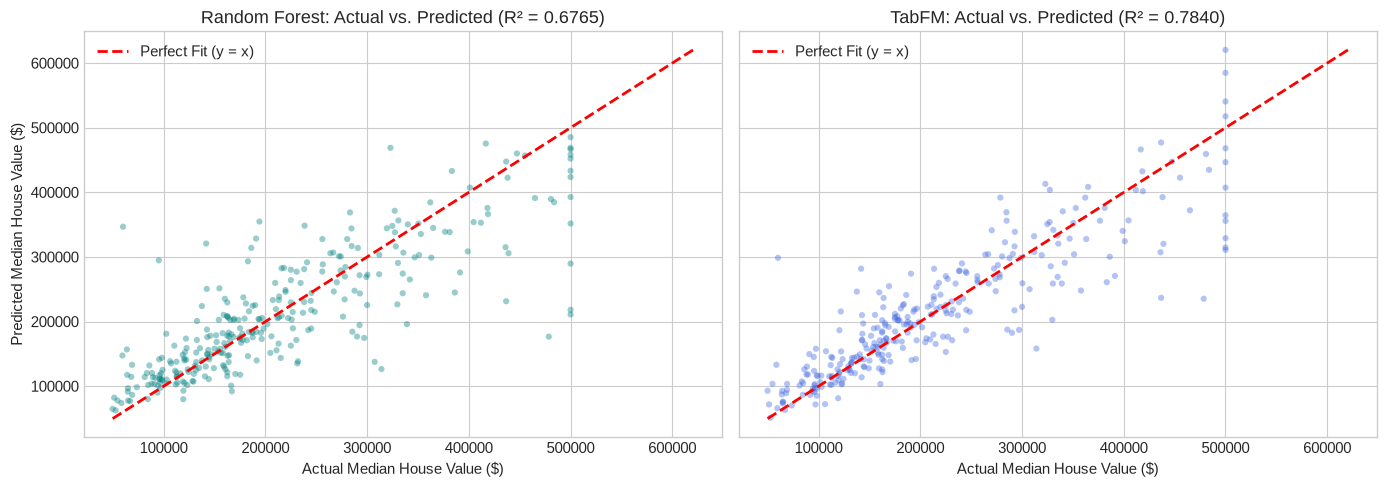

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

min_val = min(y_test_eval.min(), rf_preds.min(), tabfm_preds.min())
max_val = max(y_test_eval.max(), rf_preds.max(), tabfm_preds.max())

# 1. Random Forest
axes[0].scatter(y_test_eval, rf_preds, alpha=0.4, color="teal", s=20, edgecolor="none")
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Perfect Fit (y = x)")
axes[0].set_title(f"Random Forest: Actual vs. Predicted (R² = {rf_r2:.4f})", fontsize=13)
axes[0].set_xlabel("Actual Median House Value ($)")
axes[0].set_ylabel("Predicted Median House Value ($)")
axes[0].legend()

# 2. TabFM
axes[1].scatter(y_test_eval, tabfm_preds, alpha=0.4, color="royalblue", s=20, edgecolor="none")
axes[1].plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Perfect Fit (y = x)")
axes[1].set_title(f"TabFM: Actual vs. Predicted (R² = {tabfm_r2:.4f})", fontsize=13)
axes[1].set_xlabel("Actual Median House Value ($)")
axes[1].legend()

plt.tight_layout()
plt.show()


## 8. Residual Error Distribution Comparison

Residuals are computed as $\text{Actual} - \text{Predicted}$. A well-calibrated model produces an error distribution symmetric around zero with low spread.


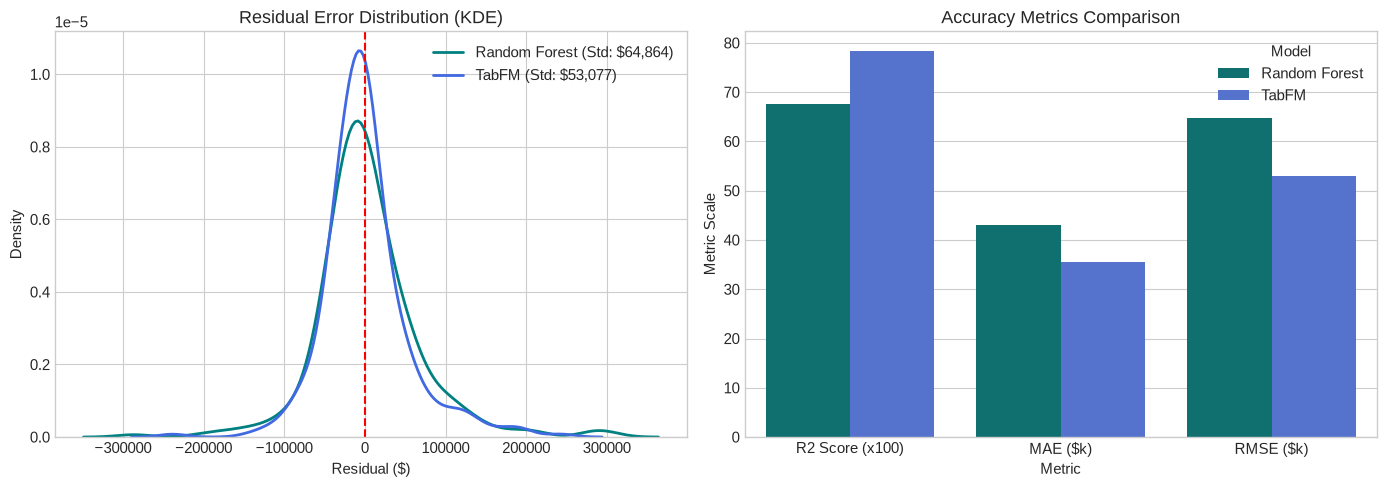

In [8]:
rf_residuals = y_test_eval - rf_preds
tabfm_residuals = y_test_eval - tabfm_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Residuals Histogram & KDE
sns.kdeplot(rf_residuals, ax=axes[0], color="teal", label=f"Random Forest (Std: ${rf_residuals.std():,.0f})", lw=2)
sns.kdeplot(tabfm_residuals, ax=axes[0], color="royalblue", label=f"TabFM (Std: ${tabfm_residuals.std():,.0f})", lw=2)
axes[0].axvline(0, color="red", linestyle="--", lw=1.5)
axes[0].set_title("Residual Error Distribution (KDE)", fontsize=13)
axes[0].set_xlabel("Residual ($)")
axes[0].set_ylabel("Density")
axes[0].legend()

# 2. Summary Metrics Comparison Bar Chart
metrics_summary = pd.DataFrame({
    "Metric": ["R2 Score (x100)", "MAE ($k)", "RMSE ($k)"],
    "Random Forest": [rf_r2 * 100, rf_mae / 1000, rf_rmse / 1000],
    "TabFM": [tabfm_r2 * 100, tabfm_mae / 1000, tabfm_rmse / 1000]
})

metrics_melted = pd.melt(metrics_summary, id_vars=["Metric"], var_name="Model", value_name="Value")
sns.barplot(data=metrics_melted, x="Metric", y="Value", hue="Model", palette=["teal", "royalblue"], ax=axes[1])
axes[1].set_title("Accuracy Metrics Comparison", fontsize=13)
axes[1].set_ylabel("Metric Scale")

plt.tight_layout()
plt.show()


## 9. Subgroup Error Analysis: Income Tiers

We segment the test samples across **Median Income Quartiles** (Low, Medium-Low, Medium-High, High) to see which model maintains superior calibration across different demographic segments.


=== Mean Absolute Error ($) Across Income Tiers ===
income_tier  samples  median_val       rf_mae    tabfm_mae  mae_diff_pct
        Low       75    119200.0 36959.943333 30651.558125     17.068168
 Medium-Low       75    155400.0 35197.136800 31789.678021      9.681068
Medium-High       75    213200.0 51476.434533 39798.918333     22.685169
       High       75    319400.0 48625.362800 39692.021667     18.371773


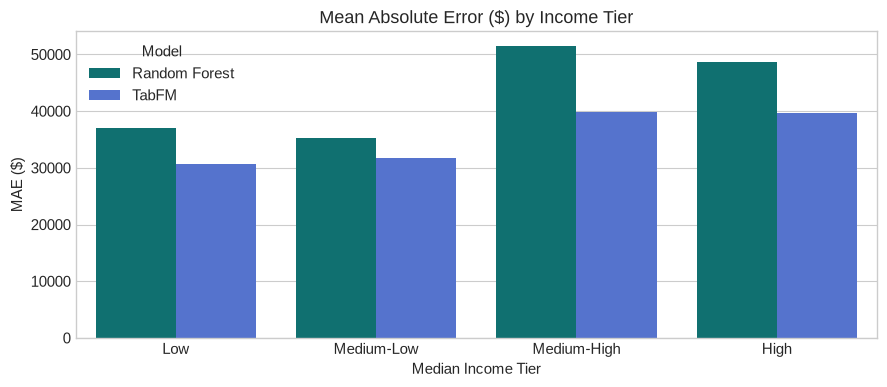

In [9]:
subgroup_df = X_test_eval.copy()
subgroup_df["actual"] = y_test_eval
subgroup_df["rf_pred"] = rf_preds
subgroup_df["tabfm_pred"] = tabfm_preds
subgroup_df["rf_mae"] = np.abs(subgroup_df["actual"] - subgroup_df["rf_pred"])
subgroup_df["tabfm_mae"] = np.abs(subgroup_df["actual"] - subgroup_df["tabfm_pred"])

subgroup_df["income_tier"] = pd.qcut(
    subgroup_df["median_income"], q=4, labels=["Low", "Medium-Low", "Medium-High", "High"]
)

tier_analysis = subgroup_df.groupby("income_tier", observed=False).agg(
    samples=("actual", "count"),
    median_val=("actual", "median"),
    rf_mae=("rf_mae", "mean"),
    tabfm_mae=("tabfm_mae", "mean")
).reset_index()

tier_analysis["mae_diff_pct"] = ((tier_analysis["rf_mae"] - tier_analysis["tabfm_mae"]) / tier_analysis["rf_mae"]) * 100

print("=== Mean Absolute Error ($) Across Income Tiers ===")
print(tier_analysis.to_string(index=False))

# Visual comparison
tier_melted = pd.melt(
    tier_analysis, id_vars=["income_tier"], value_vars=["rf_mae", "tabfm_mae"],
    var_name="Model", value_name="MAE"
)
tier_melted["Model"] = tier_melted["Model"].map({"rf_mae": "Random Forest", "tabfm_mae": "TabFM"})

plt.figure(figsize=(9, 4))
sns.barplot(data=tier_melted, x="income_tier", y="MAE", hue="Model", palette=["teal", "royalblue"])
plt.title("Mean Absolute Error ($) by Income Tier", fontsize=13)
plt.xlabel("Median Income Tier")
plt.ylabel("MAE ($)")
plt.tight_layout()
plt.show()


## 10. Summary & Engineering Takeaways

### ⚖️ Trade-Off Comparison

| Dimension | Random Forest Regressor | TabFM (Google Research) |
| :--- | :--- | :--- |
| **Sample Efficiency** | Requires thousands of samples to learn high-order non-linear interactions. | Strong accuracy with small context sets (e.g. 500–1,000 samples) via pre-trained causal graph priors. |
| **Hyperparameter Sensitivity** | Requires tuning `n_estimators`, `max_depth`, `min_samples_split`, and categorical encodings. | **Zero hyperparameter tuning** required. Operates zero-shot. |
| **Inference Latency** | **Microseconds / Milliseconds** (fast decision path traversal). | **Seconds** (scales quadratically with context length due to transformer attention). |
| **Model Footprint** | Lightweight (~few MBs of decision tree pickle). | **Large** (~6.2 GB PyTorch safetensors checkpoint). |
| **Hardware Preference** | CPU multi-threading (`n_jobs=-1`). | GPU acceleration recommended (e.g. CUDA / T4). |

### 🎯 Recommendation:
- Use **Random Forest** when high-throughput inference latency (e.g., real-time serving, low latency APIs) or low-resource CPU edge deployments are paramount.
- Use **TabFM** for cold-start environments, small-to-medium datasets, automated exploratory modeling, and applications where human tuning time is the primary bottleneck.
